# Poincaré Maps in the Earth-Moon Circular Restricted Three-Body Problem

When you integrate a trajectory in the circular restricted three-body problem (CRTBP) for a long time, the orbit in the rotating frame quickly turns into a tangle that is hard to interpret. A **Poincaré map** works like a stroboscope: instead of drawing the whole orbit, we record a single point in the $(x, v_x)$ plane every time the particle crosses the $x$ axis ($y = 0$) moving upward ($v_y > 0$).

In this notebook I build Poincaré maps for five planar orbits in the Earth-Moon system:

1. A periodic **Distant Retrograde Orbit (DRO)** from NASA/JPL's periodic orbit database.
2. A perturbed orbit near that DRO.
3. A periodic **Lyapunov orbit** around L1, also from JPL.
4. A perturbed orbit near the Lyapunov orbit.
5. An orbit with arbitrary initial conditions.

The goal is to see whether the map can tell apart the three kinds of motion Poincaré identified in this problem: **periodic**, **quasi-periodic** and **chaotic**.

## Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

## Equations of motion

I work in the rotating frame with canonical units, where the Earth sits at $x_1 = -\alpha$ and the Moon at $x_2 = 1 - \alpha$, with $\alpha = m_2/(m_1+m_2)$. The equations of motion of the test particle are:

$$\ddot{x} = x + 2\dot{y} - \frac{(1-\alpha)(x-x_1)}{r_1^3} - \frac{\alpha(x-x_2)}{r_2^3}$$
$$\ddot{y} = y - 2\dot{x} - \frac{(1-\alpha)\,y}{r_1^3} - \frac{\alpha\, y}{r_2^3}$$
$$\ddot{z} = - \frac{(1-\alpha)\,z}{r_1^3} - \frac{\alpha\, z}{r_2^3}$$

In [2]:
def eom_crtbp(t, Ys, alpha):
  x, y, z, vx, vy, vz = Ys

  # Positions of the primaries and distances to the particle
  x1 = -alpha
  r1 = np.sqrt((x-x1)**2 + y**2 + z**2)
  x2 = 1 - alpha
  r2 = np.sqrt((x-x2)**2 + y**2 + z**2)

  dvx_dt = x + 2*vy - (1-alpha)*(x-x1)/r1**3 - alpha*(x-x2)/r2**3
  dvy_dt = y - 2*vx - (1-alpha)*y/r1**3 - alpha*y/r2**3
  dvz_dt = -(1-alpha)*z/r1**3 - alpha*z/r2**3

  return [vx, vy, vz, dvx_dt, dvy_dt, dvz_dt]

For the Earth-Moon system I use the same mass ratio as the JPL database, so the initial conditions taken from there are consistent with these equations:

In [3]:
alpha = 1.215058560962404e-02 # Earth-Moon mass ratio (JPL)

## The stroboscope: detecting crossings of y = 0

`solve_ivp` supports **events**: it finds the times where a function of the state equals zero. Returning $y$ detects axis crossings, and `direction = +1` keeps only crossings where $y$ goes from negative to positive ($v_y > 0$):

In [4]:
def crossing_event(t, Ys, alpha):
  return Ys[1] # y = 0

# Keep only upward crossings (vy > 0)
crossing_event.direction = +1

A helper that integrates an orbit and returns the solution plus the map points ($x$ and $v_x$ at each crossing).

I use `DOP853` with very tight tolerances. As we will see, small errors can grow fast in this problem, so precision matters. I also compared it with the implicit `Radau` method: for the DRO over 200 time units, `Radau` took about 46 s versus under 1 s for `DOP853`.

In [5]:
def poincare_map(Y0s, t_final, n_points=20000):
  ts = np.linspace(0, t_final, n_points)
  sol = solve_ivp(eom_crtbp, [0, t_final], Y0s, t_eval=ts,
                  events=crossing_event, method='DOP853',
                  rtol=1e-12, atol=1e-12, args=(alpha,))

  # y_events[0] holds the full state at each crossing
  x_cross = sol.y_events[0][:, 0]
  vx_cross = sol.y_events[0][:, 3]
  return sol, x_cross, vx_cross

And a plotting helper: the orbit in the $(x, y)$ plane on the left (Earth in blue, Moon in gray) and the Poincaré map on the right. Map points are colored by crossing number (purple = early, yellow = late), which shows how the map builds up over time.

In [6]:
def plot_orbit_and_map(sol, x_cross, vx_cross, title, filename=None):
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))

  # Orbit in the rotating frame
  ax1.plot(sol.y[0], sol.y[1], lw=0.5)
  ax1.plot(-alpha, 0, 'bo', ms=8)
  ax1.plot(1-alpha, 0, 'o', color='gray', ms=4)
  ax1.set_xlabel('x')
  ax1.set_ylabel('y')
  ax1.set_title('Orbit (rotating frame)')
  ax1.axis('equal')
  ax1.grid()

  # Poincaré map, colored by crossing number
  order = np.arange(len(x_cross))
  pts = ax2.scatter(x_cross, vx_cross, c=order, s=12)
  fig.colorbar(pts, ax=ax2, label='Crossing number')
  ax2.set_xlabel('x')
  ax2.set_ylabel('$v_x$')
  ax2.set_title('Poincaré map')
  ax2.grid()

  fig.suptitle(title)
  plt.tight_layout()
  if filename:
    plt.savefig(filename, dpi=110)
  plt.show()

## 1. Distant Retrograde Orbit (periodic)

From JPL's [Three-Body Periodic Orbits](https://ssd.jpl.nasa.gov/tools/periodic_orbits.html) database I picked an Earth-Moon DRO with period $T \approx 1.36$ canonical units (about 6 days). It circles the Moon in the opposite direction to the Moon's own motion (hence "retrograde"), with a closest distance of about 36,000 km.

In [7]:
# DRO from the JPL database. Columns: x, y, z, vx, vy, vz
Y0_dro = [0.89577376407493814, 0, 0, 0, 0.47441396739465397, 0]
T_dro = 1.3597266610130623 # period (canonical units)

Integrating for 200 canonical units, about 147 revolutions:

Number of crossings: 148


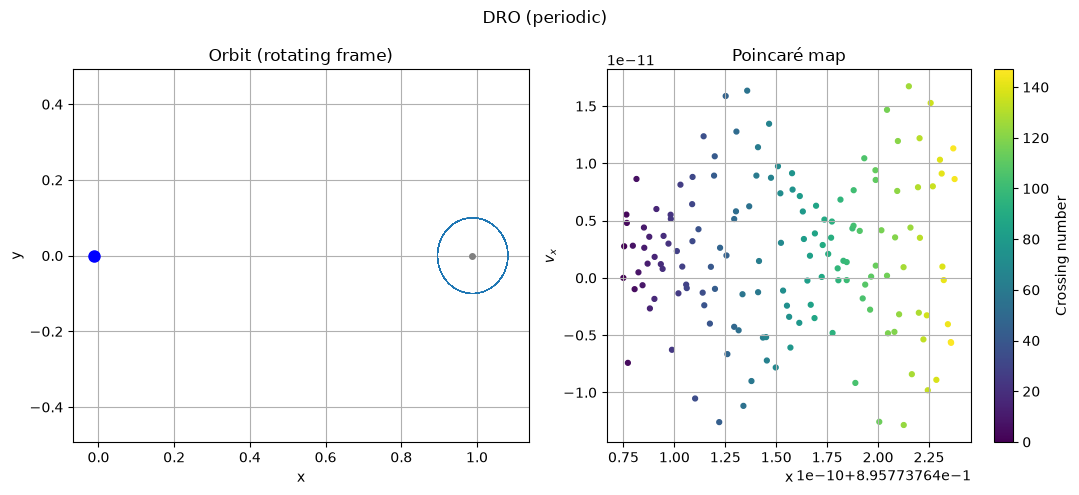

In [8]:
sol, x_c, vx_c = poincare_map(Y0_dro, 200)
print(f"Number of crossings: {len(x_c)}")
plot_orbit_and_map(sol, x_c, vx_c, 'DRO (periodic)')

The orbit is a single closed curve and every crossing lands on the same point of the map. Checking the spread:

In [9]:
print(f"Spread in x : {np.std(x_c):.2e}")
print(f"Spread in vx: {np.std(vx_c):.2e}")

Spread in x : 4.80e-11
Spread in vx: 6.39e-12


The spread is around $10^{-11}$, which is just numerical error. **A periodic orbit appears as a fixed point**: each time the particle crosses the axis it is in exactly the same state.

## 2. Perturbed DRO

Shifting the initial $x$ by 0.008 canonical units (about 3,000 km) and keeping the velocity:

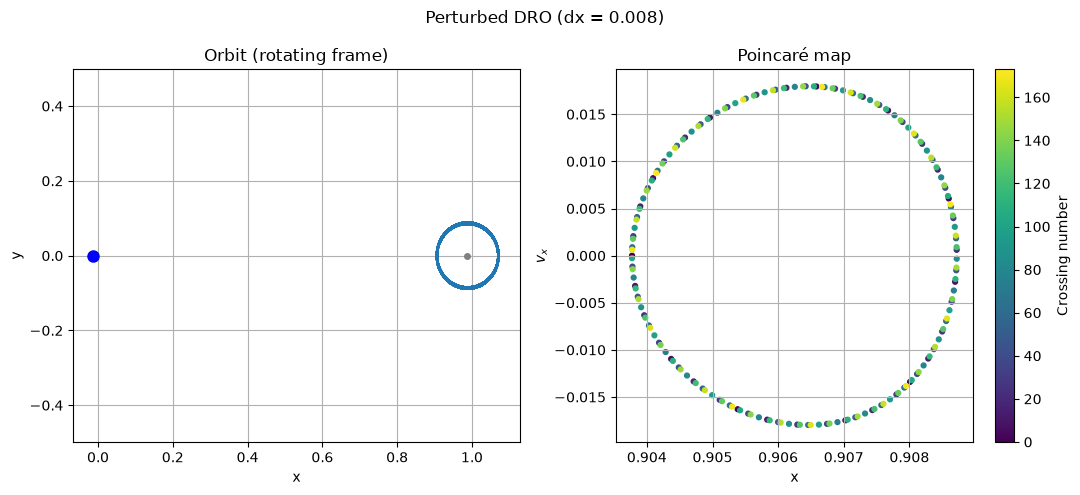

In [10]:
Y0_dro_p = [Y0_dro[0] + 0.008, 0, 0, 0, Y0_dro[4], 0]

sol, x_c, vx_c = poincare_map(Y0_dro_p, 200)
plot_orbit_and_map(sol, x_c, vx_c, 'Perturbed DRO (dx = 0.008)',
                   'dro_perturbed.png')

The orbit no longer closes and looks like a thick band in $(x, y)$. The map, however, shows it is not disordered at all: the points gradually fill a **closed curve** (the colors are mixed along the whole curve). This is a **quasi-periodic** orbit.

Overlaying several perturbation sizes:

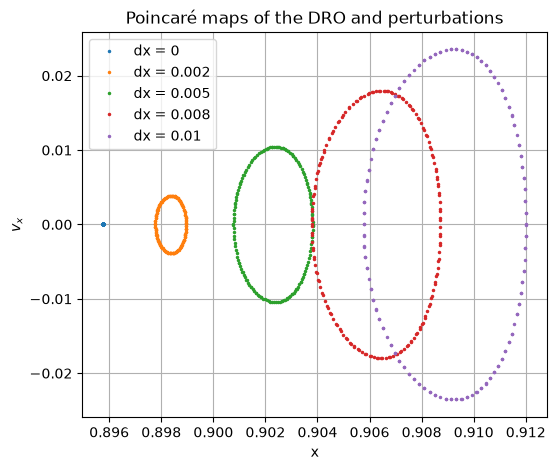

In [11]:
plt.figure(figsize=(6, 5))

for dx in [0, 0.002, 0.005, 0.008, 0.01]:
  Y0s = [Y0_dro[0] + dx, 0, 0, 0, Y0_dro[4], 0]
  sol, x_c, vx_c = poincare_map(Y0s, 200)
  plt.plot(x_c, vx_c, '.', ms=3, label=f'dx = {dx}')

plt.xlabel('x')
plt.ylabel('$v_x$')
plt.title('Poincaré maps of the DRO and perturbations')
plt.legend()
plt.grid()
plt.savefig('dro_family.png', dpi=110)
plt.show()

Every perturbation gives a closed curve, and the bigger the perturbation, the bigger the curve. The curves are not concentric because changing $x$ also changes the Jacobi constant (the "energy"), so each one surrounds a slightly different DRO. What matters is that none of them escapes or becomes disordered: the DRO is **stable**. That is consistent with the stability index of 1 listed by JPL, and it is why DROs are attractive for missions (Orion flew in a lunar DRO during Artemis I).

## 3. Lyapunov orbit around L1 (periodic)

From the same database, an L1 Lyapunov orbit with period $T \approx 6.67$ (about 30 days):

In [12]:
# L1 Lyapunov orbit from the JPL database
Y0_lyap = [0.63182735544079116, 0, 0, 0, 0.79560513558434653, 0]
T_lyap = 6.6741349764237441 # period (canonical units)

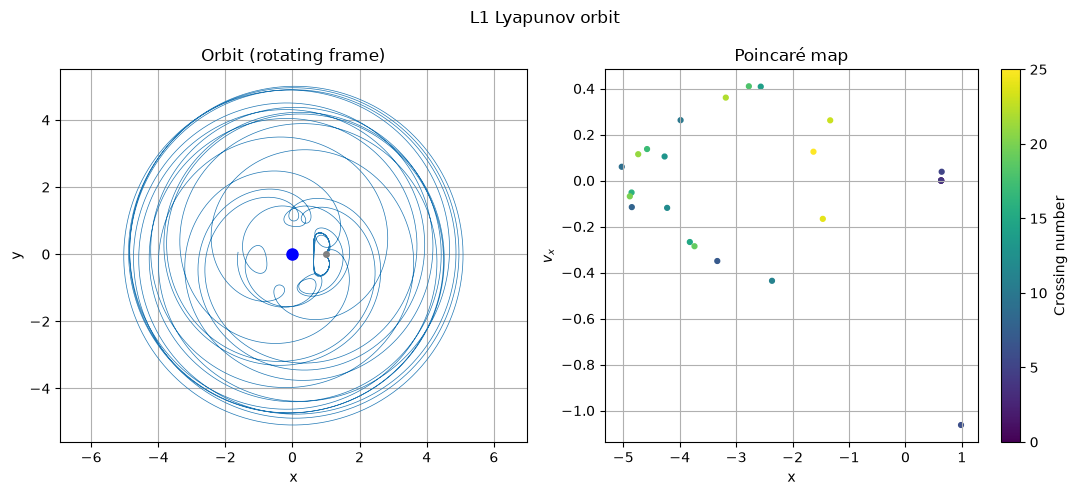

In [13]:
sol, x_c, vx_c = poincare_map(Y0_lyap, 200)
plot_orbit_and_map(sol, x_c, vx_c, 'L1 Lyapunov orbit')

This doesn't look periodic: the orbit makes a few loops near L1 and then escapes. Looking at the first crossings:

In [14]:
for i in range(8):
  print(f"Crossing {i+1}: x = {x_c[i]:.6f}, vx = {vx_c[i]:+.6f}")

Crossing 1: x = 0.631827, vx = +0.000000
Crossing 2: x = 0.631827, vx = +0.000000
Crossing 3: x = 0.631827, vx = +0.000000
Crossing 4: x = 0.631828, vx = +0.000003
Crossing 5: x = 0.631915, vx = +0.000348
Crossing 6: x = 0.641890, vx = +0.038394
Crossing 7: x = 0.984199, vx = -1.062682
Crossing 8: x = -3.334446, vx = -0.349681


The first 3 crossings land on exactly the same point, so the orbit **is periodic**, but from the 4th crossing on it drifts away. The reason is that Lyapunov orbits are **unstable**: JPL lists a stability index of 54 for this one (the DRO had 1). Any tiny error, even the $10^{-12}$ error of the integrator, gets multiplied by roughly 100 every revolution, and after 5 or 6 revolutions it is as large as the orbit itself.

Integrating only 3 periods shows the periodic part:

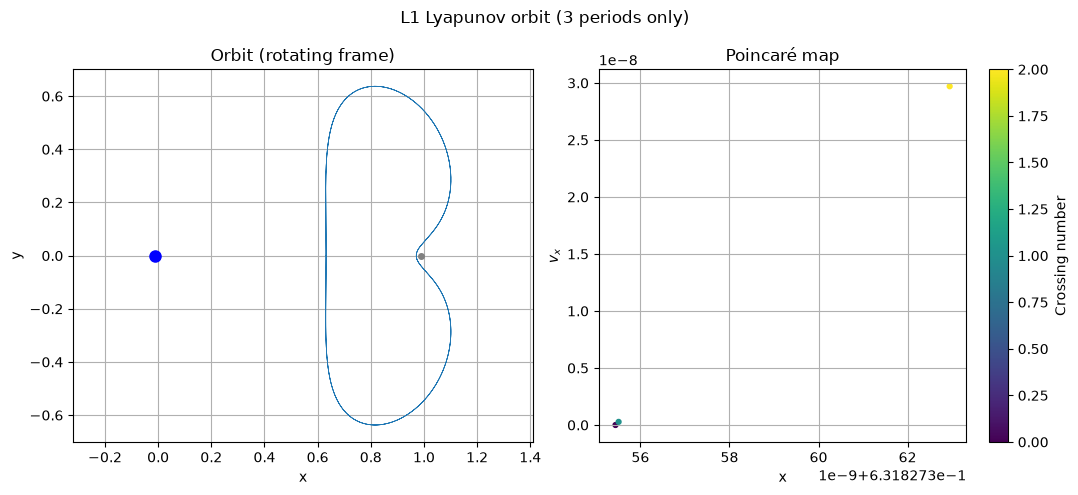

In [15]:
sol, x_c, vx_c = poincare_map(Y0_lyap, 3*T_lyap)
plot_orbit_and_map(sol, x_c, vx_c, 'L1 Lyapunov orbit (3 periods only)')

Over those 3 periods the map is a single fixed point, just like the DRO.

## 4. Perturbed Lyapunov orbit

Shifting the initial $x$ by 0.005:

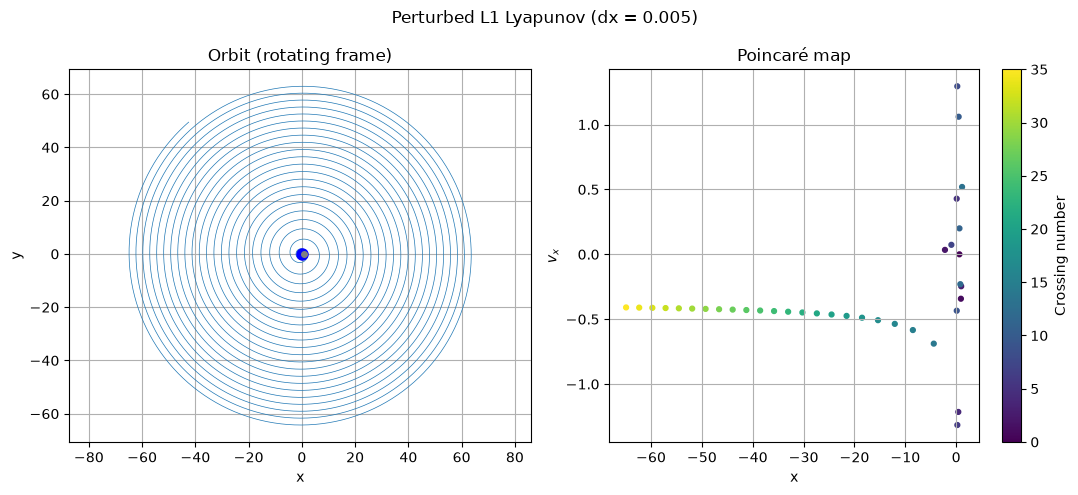

In [16]:
Y0_lyap_p = [Y0_lyap[0] + 0.005, 0, 0, 0, Y0_lyap[4], 0]

sol, x_c, vx_c = poincare_map(Y0_lyap_p, 200)
plot_orbit_and_map(sol, x_c, vx_c, 'Perturbed L1 Lyapunov (dx = 0.005)')

The particle leaves L1 from the first loop, wanders near the Moon and ends up escaping the system (in the rotating frame a distant, almost static particle appears to spiral). While it is near the Moon (early crossings, in purple) the map points are scattered with no curve at all; the line of green and yellow points is just the particle receding after the escape. This is **chaotic** behavior: unlike the DRO, a small perturbation does not produce a similar orbit but a completely different one.

## 5. Arbitrary initial conditions

For the last case I place the particle at $x = 0.8$, between the Earth and the Moon, with a small upward velocity $v_y = 0.15$. I tried several options and chose this one because the particle stays in the system without colliding with either body. I integrate a bit longer (300 units) to get more points:

Number of crossings: 76


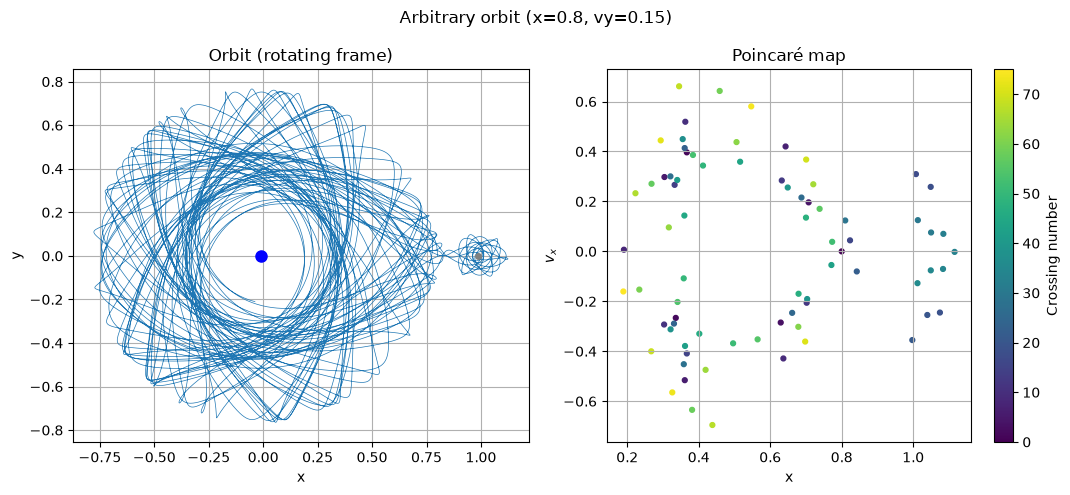

In [17]:
Y0_arb = [0.8, 0, 0, 0, 0.15, 0]

sol, x_c, vx_c = poincare_map(Y0_arb, 300, n_points=30000)
print(f"Number of crossings: {len(x_c)}")
plot_orbit_and_map(sol, x_c, vx_c, 'Arbitrary orbit (x=0.8, vy=0.15)',
                   'chaotic_orbit.png')

The $(x, y)$ plot is exactly the tangle mentioned at the start: the particle circles the Earth, sometimes passes through the L1 neck to loop around the Moon, and comes back. The map is neither a point nor a curve but a **scattered cloud** of points. This is a **chaotic** but bounded orbit.

### Is the disorder just numerical error?

To make sure the scatter is physical, I check the **Jacobi constant**, which is conserved in the CRTBP:

$$C_J = x^2 + y^2 + \frac{2(1-\alpha)}{r_1} + \frac{2\alpha}{r_2} - (v_x^2 + v_y^2)$$

(For the DRO this formula gives $C_J = 3.0173$, the same value listed by JPL.)

In [18]:
def jacobi(Ys, alpha):
  x, y, z, vx, vy, vz = Ys
  r1 = np.sqrt((x+alpha)**2 + y**2 + z**2)
  r2 = np.sqrt((x-1+alpha)**2 + y**2 + z**2)
  return x**2 + y**2 + 2*(1-alpha)/r1 + 2*alpha/r2 - (vx**2 + vy**2)

print(f"C_J of the DRO: {jacobi(Y0_dro, alpha):.5f}")

CJ = jacobi(sol.y, alpha)
print(f"Relative variation of C_J along the arbitrary orbit: "
      f"{np.max(np.abs(CJ - CJ[0]))/abs(CJ[0]):.1e}")

C_J of the DRO: 3.01733
Relative variation of C_J along the arbitrary orbit: 1.6e-10


The Jacobi constant is conserved to about $10^{-10}$, so the integration is reliable and the scatter in the map is genuine chaos.

## Telling the three types apart

Each type of orbit leaves a different fingerprint on the map:

| Orbit type | Appearance on the map | Examples here |
|---|---|---|
| **Periodic** | A single point (or a few fixed points) | DRO, Lyapunov during its first periods |
| **Quasi-periodic** | Points filling a closed curve | Perturbed DRO |
| **Chaotic** | Scattered points filling a region | Perturbed Lyapunov, arbitrary orbit |

Why this works: since the Jacobi constant is conserved and we fix $y = 0$ and $v_y > 0$, the state at each crossing is fully determined by $(x, v_x)$, so this 2D map captures the whole motion.

- A **periodic** orbit returns to the same state every period, so the stroboscope always sees it in the same place.
- A **quasi-periodic** orbit combines two incommensurable frequencies: it never repeats exactly but stays on a torus in phase space, and the slice of that torus at $y = 0$ is the closed curve.
- A **chaotic** orbit is not confined to any torus, so its crossings land seemingly at random across the region allowed by the Jacobi constant.

In the $(x, y)$ plots the perturbed DRO and the arbitrary orbit look equally tangled; only the Poincaré map reveals that one is ordered and the other is not.

## Summary

- Poincaré maps were built by detecting upward crossings of $y = 0$ with `solve_ivp` events.
- The JPL DRO is a fixed point of the map, and perturbing it produces closed curves: the DRO is stable and nearby orbits are quasi-periodic.
- The L1 Lyapunov orbit is periodic but unstable: it holds for about 3 periods before numerical error grows and the particle escapes. Its perturbed version is chaotic from the start. Being periodic is not enough; stability matters.
- The arbitrary orbit is chaotic, and the conserved Jacobi constant ($10^{-10}$ error) confirms this is not a numerical artifact.

## References

- NASA/JPL, *Three-Body Periodic Orbits*: https://ssd.jpl.nasa.gov/tools/periodic_orbits.html
- Murray, C. D. & Dermott, S. F. (1999). *Solar System Dynamics*. Cambridge University Press, chapter 3.
- SciPy documentation, `scipy.integrate.solve_ivp` (event handling).